# Business Establishments — Two Agencies, Opposite Ways to Hide the Same Thing

**Artifact class:** `tutorial`  ·  **Data mode:** `empirical`  ·  **Vintage:** Census CBP 2022, BLS QCEW 2022 Q1 (reference periods; NOT pinned vintages)

D09 established that BLS **withholds** a QCEW cell when disclosing it could identify an employer,
and publishes the withheld value as `0`. The Census Bureau measures nearly the same quantity in
County Business Patterns and protects it the **opposite** way: it publishes a value for every cell
it publishes, perturbed by noise infusion, and simply **omits** the cells it will not publish.

Compare the two on one county and the naive reading is that CBP is the cleaner source. Every cell
has a value. No suppression flags. Nothing to filter.

That reading is exactly backwards, and this notebook is about why.

> QCEW lists **692** six-digit industries in Fairfax County. CBP lists **469**. Of the industries
> QCEW lists and CBP omits, QCEW openly reports employment for **120 of them, totalling nearly
> 60,000 jobs** — absent from CBP with no flag, no zero, and no row.

**Visible gaps are better than invisible ones**, and the source that looks tidier is the one whose
omissions you cannot see.

Real data only. No synthetic fallback. *Proprietary. SPDX-License-Identifier: LicenseRef-Proprietary*

## Learning Objectives

1. **Contrast** two disclosure-limitation strategies — withholding with a flag, and omission with
   noise infusion — and derive what each one allows and prevents.
2. **Detect** silent omission by comparing an industry roster against a second source, since a
   missing row leaves no trace in the response that contains it.
3. **Quantify** the employment that one source reports openly and the other does not publish at all.
4. **Read** a noise flag for what it does and does not tell you, and state the limit when the
   publisher documents a protection it does not let you measure.
5. **Reconcile** two near-identical concepts across agencies where both disclose, and attribute the
   residual difference to definition rather than to error.
6. **Choose** between two sources on the basis of which failure mode the analysis can tolerate.

## Prerequisites

**Knowledge.** D09 (QCEW and disclosure suppression) is a hard prerequisite — this notebook is its
counterpart. D02 is useful for the BLS side.

**Setup.** `CENSUS_API_KEY` for CBP. QCEW needs no credential.

**Packages.** `pandas`, `numpy`, `matplotlib`, and `krl_tutorials_data`.

## Data Provenance

| Source | What | Protection strategy |
|---|---|---|
| **Census CBP 2022** | Establishments, employment, payroll by county and NAICS | **Noise infusion**, plus silent omission of unpublished cells |
| **BLS QCEW 2022 Q1** | The same, from unemployment-insurance records | **Suppression** with a `disclosure_code` flag; withheld values written as `0` |

**The two are comparable on purpose.** CBP's reference period is the pay period including 12 March;
QCEW's `month3_emplvl` in Q1 is March employment. Both count establishments rather than firms, and
both are administrative records rather than surveys — so neither carries a margin of error, and a
difference between them is definitional or procedural, never sampling.

**Where they genuinely differ.** CBP is drawn from the Business Register and excludes most
government, agricultural production and self-employed persons without payroll. QCEW covers
employers subject to unemployment-insurance law. The private-sector comparison below narrows the
gap but does not close it, and the residual is not attributed here.

In [1]:
"""Configuration. Counties span size, because disclosure pressure scales with it."""
from __future__ import annotations

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

_here = Path.cwd().resolve()
for _cand in (_here, *_here.parents):
    if (_cand / "src" / "krl_tutorials_data").is_dir():
        sys.path.insert(0, str(_cand / "src")); break
else:
    raise SystemExit("Could not locate krl_tutorials_data from " + str(_here))

from krl_tutorials_data.sources import (
    verify_digest,
    fetch_cbp, fetch_qcew, DataAccessError, CBP_NOISE_FLAGS,
)

CBP_YEAR = 2022
QCEW_YEAR, QCEW_QUARTER = 2022, 1
PRIVATE_OWNERSHIP = "5"
SIX_DIGIT_AGGLVL = "78"
NAICS_DEPTH = 6

COUNTIES = {
    ("51", "059"): "Fairfax County, VA",
    ("51", "013"): "Arlington County, VA",
    ("51", "750"): "Radford city, VA",
    ("51", "720"): "Norton city, VA",
}
FOCUS = ("51", "059")

CBP_VARIABLES = {
    "EMP": "Number of employees (pay period including 12 March)",
    "EMP_N": "Noise range flag for EMP",
    "ESTAB": "Number of establishments",
    "NAICS2017": "NAICS 2017 industry code",
}

pd.set_option("display.width", 150)
plt.rcParams["figure.dpi"] = 110

print(f"CBP vintage   : {CBP_YEAR}")
print(f"QCEW vintage  : {QCEW_YEAR} Q{QCEW_QUARTER} (March employment)")
print(f"Counties      : {len(COUNTIES)}")
for _fips, _name in COUNTIES.items():
    print(f"  {''.join(_fips)}  {_name}")
print(f"Industry depth: {NAICS_DEPTH}-digit NAICS")
print(f"CBP noise flags recognised: {', '.join(CBP_NOISE_FLAGS)}")
print("Credentials   : CENSUS_API_KEY for CBP; QCEW needs none")

#: One digest per county per source. CBP and QCEW are both revised and both
#: serve only the current release, so the year and quarter name reference
#: periods. These pins do not restore a vintage -- they guarantee a revision
#: raises here rather than changing the comparison below.
PINNED_CBP = {
    "51013": "3886b68c99613be6f8ff2d399188367e4c0309fb17955d041dc84d2776abfb1a",
    "51059": "d6122c2314b37fd571d1a6b07efae3d3446a4b44e091ca85c6b6e74667a3921d",
    "51720": "4b1936a9c9f3291e47301e83fb7af59911353360e1fc1e92334833e2b6072bf9",
    "51750": "904cab2781d328ca089620b8c719b1c1765199ec3b36465092372186c94e16d6",
}
PINNED_QCEW = {
    "51013": "026afdab3be91b5f5ce98e81c0eb34f8071d0a88c3ff86af50311b405f7767bb",
    "51059": "d8c8576c17c1469875fa7d4bdeb0b7fff13182c8bc7c610274018bebf052b02b",
    "51720": "db36733bcbc379dae364c040048282edac5a6910a425d320255ce1e7ea9f69cb",
    "51750": "8ac796244e3fc16e881a1aa5bc687dedb1ee4364f76e7bf68c6d5829ca55fc92",
}


CBP vintage   : 2022
QCEW vintage  : 2022 Q1 (March employment)
Counties      : 4
  51059  Fairfax County, VA
  51013  Arlington County, VA
  51750  Radford city, VA
  51720  Norton city, VA
Industry depth: 6-digit NAICS
CBP noise flags recognised: EMP_N, PAYANN_N
Credentials   : CENSUS_API_KEY for CBP; QCEW needs none


In [2]:
def load_county(state: str, county: str):
    """Both sources for one county, narrowed to comparable private six-digit cells."""
    cbp, cbp_prov = verify_digest(
        fetch_cbp(year=CBP_YEAR, variables=CBP_VARIABLES,
                  geography=f"county:{county}", within=f"state:{state}"),
        PINNED_CBP[f"{state}{county}"], label=f"CBP {state}{county}",
    )
    cbp_six = cbp.loc[cbp.NAICS2017.str.len() == NAICS_DEPTH].copy()

    qcew, qcew_prov = verify_digest(
        fetch_qcew(year=QCEW_YEAR, quarter=QCEW_QUARTER, area=f"{state}{county}"),
        PINNED_QCEW[f"{state}{county}"], label=f"QCEW {state}{county}",
    )
    qcew_six = qcew.loc[
        (qcew.own_code == PRIVATE_OWNERSHIP) & (qcew.agglvl_code == SIX_DIGIT_AGGLVL)
    ].copy()
    return cbp_six, qcew_six, cbp_prov, qcew_prov


try:
    data, provenance = {}, {}
    for _fips in COUNTIES:
        _c, _q, _cp, _qp = load_county(*_fips)
        data[_fips] = (_c, _q)
        provenance[f"cbp_{''.join(_fips)}"] = _cp
        provenance[f"qcew_{''.join(_fips)}"] = _qp
except DataAccessError as exc:
    print("HALTED - real data could not be obtained.")
    print(f"  failure class : {type(exc).__name__}")
    print(f"  detail        : {exc}")
    print("\nNo synthetic fallback exists by design.")
    raise

cbp_focus, qcew_focus = data[FOCUS]
print(f"{COUNTIES[FOCUS]}")
print(f"  CBP  {NAICS_DEPTH}-digit rows : {len(cbp_focus):>5}")
print(f"  QCEW {NAICS_DEPTH}-digit rows : {len(qcew_focus):>5}  "
      f"({int(qcew_focus.suppressed.sum())} suppressed)")
print()
print(provenance[f"cbp_{''.join(FOCUS)}"].render())

Fairfax County, VA
  CBP  6-digit rows :   469
  QCEW 6-digit rows :   692  (297 suppressed)

Source      : U.S. Census Bureau - County Business Patterns 2022
Vintage     : 2022  (pinned)
Endpoint    : https://api.census.gov/data/2022/cbp
Retrieved   : 2026-09-18T12:41:19+00:00
Shape       : 1150 rows x 6 cols
Payload hash: d6122c2314b37fd5...  (canonical-rows)
Data mode   : EMPIRICAL
Variables   :
              EMP              Number of employees (pay period including 12 March)
              EMP_N            Noise range flag for EMP
              ESTAB            Number of establishments
              NAICS2017        NAICS 2017 industry code
Limitations :
              - CBP counts establishments from the Business Register; these are not survey estimates and carry no margin of error.
              - Confidentiality is protected by NOISE INFUSION, not suppression: a published value may be perturbed. Flag column(s) present: EMP_N.
              - CBP omits industry cells it does not p

## 1. Which source looks cleaner, and which one is

The first table is the one that misleads. CBP has no suppression flag to report, so a column
counting withheld cells reads zero, and QCEW looks like the compromised source.

In [3]:
rows = []
for fips, (cbp, qcew) in data.items():
    rows.append({
        "county": COUNTIES[fips],
        "cbp_cells": len(cbp),
        "cbp_missing_values": int(cbp.EMP.isna().sum()),
        "qcew_cells": len(qcew),
        "qcew_withheld": int(qcew.suppressed.sum()),
        "qcew_withheld_pct": float(qcew.suppressed.mean() * 100),
    })
surface = pd.DataFrame(rows)
print("The naive comparison")
print(surface.to_string(index=False, formatters={"qcew_withheld_pct": "{:.1f}".format}))
print()
print("Read this way, CBP publishes a value for every cell and QCEW withholds up to")
print(f"{surface.qcew_withheld_pct.max():.0f}% of its own. CBP appears to be the more complete source.")
print()
print("But the two 'cells' columns are not comparable, because they count different")
print("things: QCEW's count includes the industries it withholds, and CBP's does not")
print("include the industries it omits. The next section counts what is actually there.")

The naive comparison
              county  cbp_cells  cbp_missing_values  qcew_cells  qcew_withheld qcew_withheld_pct
  Fairfax County, VA        469                   0         692            297              42.9
Arlington County, VA        267                   0         513            304              59.3
    Radford city, VA         30                   0         150            134              89.3
     Norton city, VA         16                   0         113            101              89.4

Read this way, CBP publishes a value for every cell and QCEW withholds up to
89% of its own. CBP appears to be the more complete source.

But the two 'cells' columns are not comparable, because they count different
things: QCEW's count includes the industries it withholds, and CBP's does not
include the industries it omits. The next section counts what is actually there.


## 2. The rosters disagree about which industries exist

Neither source claims to list every industry in a county. The question is whether you can *tell*
which ones are absent — and here the strategies diverge completely.

QCEW lists the industry, discloses its establishment count, and flags the employment as withheld.
CBP omits the row. Nothing in a CBP response indicates that an industry was considered and not
published, so the only way to detect it is to hold a second roster against it.

In [4]:
cbp_codes = set(cbp_focus.NAICS2017)
qcew_codes = set(qcew_focus.industry_code)
both = cbp_codes & qcew_codes
qcew_only = qcew_codes - cbp_codes
cbp_only = cbp_codes - qcew_codes

print(f"{COUNTIES[FOCUS]}, {NAICS_DEPTH}-digit industries")
print(f"  listed by QCEW            : {len(qcew_codes):>5}")
print(f"  listed by CBP             : {len(cbp_codes):>5}")
print(f"  listed by both            : {len(both):>5}")
print(f"  QCEW only (CBP omits)     : {len(qcew_only):>5}")
print(f"  CBP only (QCEW omits)     : {len(cbp_only):>5}")
print()

orphans = qcew_focus.loc[qcew_focus.industry_code.isin(qcew_only)]
disclosed_orphans = orphans.loc[~orphans.suppressed]
orphan_jobs = float(disclosed_orphans.month3_emplvl.sum())

print(f"Of the {len(qcew_only)} industries QCEW lists and CBP does not:")
print(f"  QCEW also withholds employment for  {int(orphans.suppressed.sum()):>4} "
      f"({orphans.suppressed.mean():.0%})")
print(f"  QCEW openly reports employment for  {len(disclosed_orphans):>4}")
print(f"    totalling {orphan_jobs:,.0f} employees, median "
      f"{disclosed_orphans.month3_emplvl.median():,.0f} per industry")
print()
print("Those jobs are not marked missing in CBP. They are not zero in CBP. There is no")
print("row for them at all, and a reader working from CBP alone has no way to learn")
print("that the industries exist - which is precisely what QCEW's flag tells you.")

Fairfax County, VA, 6-digit industries
  listed by QCEW            :   692
  listed by CBP             :   469
  listed by both            :   365
  QCEW only (CBP omits)     :   327
  CBP only (QCEW omits)     :   104

Of the 327 industries QCEW lists and CBP does not:
  QCEW also withholds employment for   207 (63%)
  QCEW openly reports employment for   120
    totalling 59,834 employees, median 186 per industry

Those jobs are not marked missing in CBP. They are not zero in CBP. There is no
row for them at all, and a reader working from CBP alone has no way to learn
that the industries exist - which is precisely what QCEW's flag tells you.


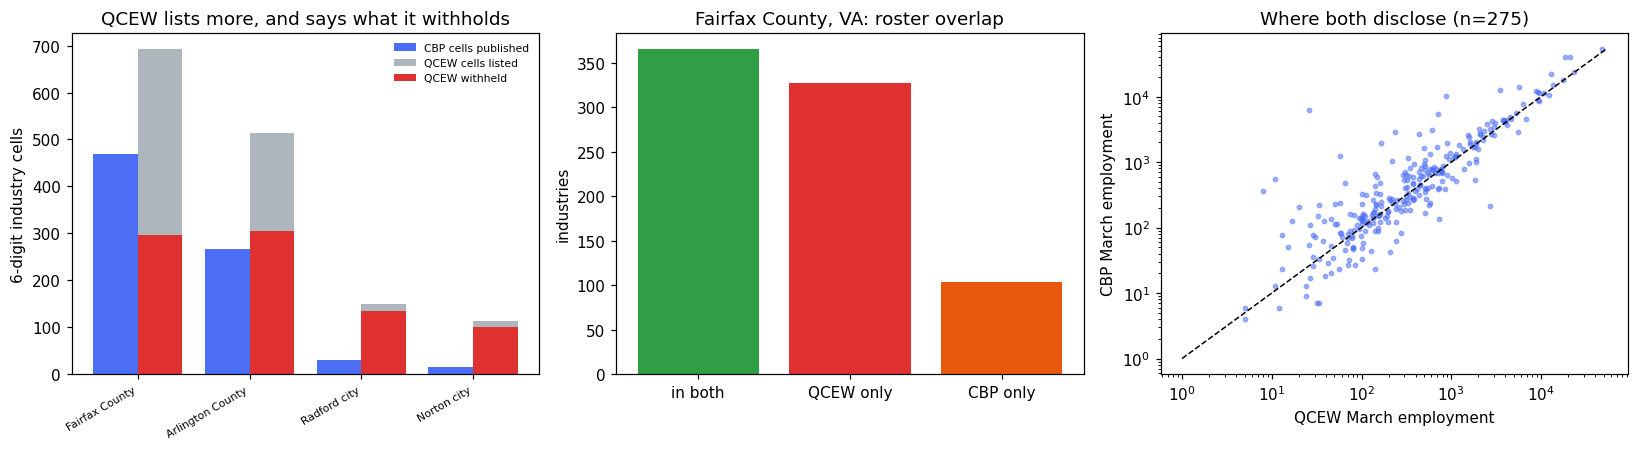

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

x = np.arange(len(surface))
axes[0].bar(x - 0.2, surface.cbp_cells, width=0.4, label="CBP cells published",
            color="#4c6ef5")
axes[0].bar(x + 0.2, surface.qcew_cells, width=0.4, label="QCEW cells listed",
            color="#adb5bd")
axes[0].bar(x + 0.2, surface.qcew_withheld, width=0.4,
            label="QCEW withheld", color="#e03131")
axes[0].set_xticks(x)
axes[0].set_xticklabels([c.split(",")[0] for c in surface.county],
                        rotation=30, ha="right", fontsize=7)
axes[0].set_ylabel(f"{NAICS_DEPTH}-digit industry cells")
axes[0].set_title("QCEW lists more, and says what it withholds")
axes[0].legend(frameon=False, fontsize=7)

axes[1].bar(["in both", "QCEW only", "CBP only"],
            [len(both), len(qcew_only), len(cbp_only)],
            color=["#2f9e44", "#e03131", "#e8590c"])
axes[1].set_ylabel("industries")
axes[1].set_title(f"{COUNTIES[FOCUS]}: roster overlap")

shared = (cbp_focus.set_index("NAICS2017").loc[sorted(both), ["EMP"]]
          .join(qcew_focus.set_index("industry_code")[["month3_emplvl", "suppressed"]])
          .rename(columns={"EMP": "cbp_emp", "month3_emplvl": "qcew_emp"}))
comparable = shared.loc[~shared.suppressed.astype(bool)].dropna()
axes[2].scatter(comparable.qcew_emp, comparable.cbp_emp, s=8, alpha=.5, color="#4c6ef5")
_lim = [1, max(comparable.qcew_emp.max(), comparable.cbp_emp.max())]
axes[2].plot(_lim, _lim, "k--", lw=1)
axes[2].set_xscale("log"); axes[2].set_yscale("log")
axes[2].set_xlabel("QCEW March employment"); axes[2].set_ylabel("CBP March employment")
axes[2].set_title(f"Where both disclose (n={len(comparable)})")
plt.tight_layout(); plt.show()

## 3. Where both disclose, do they agree? Not really

On the industries both sources publish, the numbers ought to be close — same month, same
establishment concept, both administrative. Testing that is the point of this section, and the
answer constrains what the roster comparison above is allowed to conclude.

They move together and they do not agree in level. Holding that distinction is the whole exercise:
correlation is not agreement, and a scatter that looks convincing on log axes can hide a systematic
gap and a long tail of two-fold disagreements.

In [6]:
comparable = comparable.assign(
    ratio=comparable.cbp_emp / comparable.qcew_emp.replace(0, np.nan),
    diff=comparable.cbp_emp - comparable.qcew_emp,
).dropna(subset=["ratio"])

print(f"{len(comparable)} industries disclosed by both sources")
print(f"  correlation (log employment) : "
      f"{np.corrcoef(np.log(comparable.qcew_emp.clip(lower=1)), np.log(comparable.cbp_emp.clip(lower=1)))[0, 1]:.4f}")
print(f"  median CBP/QCEW ratio        : {comparable.ratio.median():.4f}")
print(f"  within 10% of each other     : "
      f"{int(comparable.ratio.between(0.9, 1.1).sum())} of {len(comparable)} "
      f"({comparable.ratio.between(0.9, 1.1).mean():.1%})")
print(f"  differ by more than 2x       : "
      f"{int(((comparable.ratio > 2) | (comparable.ratio < 0.5)).sum())}")
print()
print(f"  total employment, shared industries only:")
print(f"    CBP  {comparable.cbp_emp.sum():>12,.0f}")
print(f"    QCEW {comparable.qcew_emp.sum():>12,.0f}")
print(f"    CBP/QCEW {comparable.cbp_emp.sum() / comparable.qcew_emp.sum():.4f}")
print()
_within = comparable.ratio.between(0.9, 1.1).mean()
_wild = float(((comparable.ratio > 2) | (comparable.ratio < 0.5)).mean())
print("These two sources move together and do NOT agree in level. They correlate well on")
print(f"log employment, yet only {_within:.0%} of shared industries are within 10% of each other")
print(f"and {_wild:.0%} differ by more than a factor of two, with CBP running "
      f"{comparable.cbp_emp.sum() / comparable.qcew_emp.sum() - 1:+.0%} higher in total.")
print()
print("That has a consequence for section 2, and it cuts against the simple reading.")
print("If the two sources disagreed only about DISCLOSURE, they would agree about")
print("MAGNITUDE where both disclose. They do not, so their universes genuinely differ -")
print("as the documentation says: CBP excludes most government, agricultural production")
print("and the self-employed without payroll, and the two registers allocate multi-unit")
print("firms differently.")
print()
print("So the 327 industries in QCEW and not in CBP cannot be attributed purely to")
print("disclosure policy. Some are outside CBP's universe altogether. And that is the")
print("sharper version of this notebook's point: with silent omission you cannot tell")
print("the two apart. QCEW's flag at least tells you the industry exists in ITS universe.")

275 industries disclosed by both sources
  correlation (log employment) : 0.8753
  median CBP/QCEW ratio        : 1.1341
  within 10% of each other     : 46 of 275 (16.7%)
  differ by more than 2x       : 76

  total employment, shared industries only:
    CBP       543,475
    QCEW      416,570
    CBP/QCEW 1.3046

These two sources move together and do NOT agree in level. They correlate well on
log employment, yet only 17% of shared industries are within 10% of each other
and 28% differ by more than a factor of two, with CBP running +30% higher in total.

That has a consequence for section 2, and it cuts against the simple reading.
If the two sources disagreed only about DISCLOSURE, they would agree about
MAGNITUDE where both disclose. They do not, so their universes genuinely differ -
as the documentation says: CBP excludes most government, agricultural production
and the self-employed without payroll, and the two registers allocate multi-unit
firms differently.

So the 327 industri

## 4. The noise flag, and the limit of what it tells you

CBP's protection is noise infusion, and the Bureau publishes flag columns describing the noise
range applied to each value. Reading those flags is the correct way to know how much a CBP figure
may have been perturbed.

In these slices the flag does not carry that information, and saying so is the honest result.

In [7]:
flags = cbp_focus.EMP_N.fillna("<blank>").value_counts()
print(f"EMP_N flag distribution, {COUNTIES[FOCUS]} ({len(cbp_focus)} cells)")
for value, count in flags.items():
    print(f"  {value!r:<12} {count:>5}  ({count / len(cbp_focus):.1%})")
print()
print("Across all four counties:")
_all = pd.concat([c.EMP_N.fillna("<blank>") for c, _ in data.values()])
for value, count in _all.value_counts().items():
    print(f"  {value!r:<12} {count:>5}  ({count / len(_all):.1%})")
print()
print("The flag is uniform, and the API's variable metadata for EMP_N publishes no")
print("enumeration of its possible values. So the noise range applied to any particular")
print("figure cannot be read from this response.")
print()
print("That is a limitation to state, not a problem to solve here: the protection is")
print("documented by the Bureau and is not quantifiable from the data it returns. An")
print("analysis that needs to bound the perturbation has to go to the methodology, and")
print("an analysis that cannot tolerate an unquantified perturbation should use the")
print("source that withholds instead - which is the trade this notebook is about.")

EMP_N flag distribution, Fairfax County, VA (469 cells)
  '0'            469  (100.0%)

Across all four counties:
  '0'            782  (100.0%)

The flag is uniform, and the API's variable metadata for EMP_N publishes no
enumeration of its possible values. So the noise range applied to any particular
figure cannot be read from this response.

That is a limitation to state, not a problem to solve here: the protection is
documented by the Bureau and is not quantifiable from the data it returns. An
analysis that needs to bound the perturbation has to go to the methodology, and
an analysis that cannot tolerate an unquantified perturbation should use the
source that withholds instead - which is the trade this notebook is about.


## Limitations

- **Four counties in one state.** They illustrate a contrast; they are not a sample, and no
  quantity here should be read as a national figure.
- **The universes genuinely differ.** CBP excludes most government, agricultural production and
  the self-employed without payroll; QCEW covers UI-subject employment. The private six-digit
  comparison narrows this and does not eliminate it, and the residual is not decomposed.
- **The roster comparison cannot separate disclosure from existence.** An industry in QCEW and not
  in CBP may have been omitted for disclosure reasons *or* may fall outside CBP's universe. The
  120 industries where QCEW discloses employment are the ones where that ambiguity is smallest, and
  even there it is not zero.
- **Noise magnitude is unquantified**, as section 4 establishes. Comparisons involving CBP values
  inherit a perturbation of unknown size.
- **One year, one quarter.** CBP is annual with a March reference; QCEW Q1 is used to match it.
  Neither source's revision behaviour is examined.
- **No margins of error exist on either side.** Both are administrative counts, so no difference
  here is testable against sampling error, and none is claimed to be.
- **No causal claim.** Nothing identifies why any industry is present, absent, or sized as it is.

In [8]:
"""Findings. Every number below is rendered from a value computed above."""
print("FINDINGS")
print("=" * 78)
print(f"1. On the surface CBP looks like the cleaner source: it publishes a value for every")
print(f"   one of its {len(cbp_focus):,} {NAICS_DEPTH}-digit cells in {COUNTIES[FOCUS]}, while QCEW withholds")
print(f"   {int(qcew_focus.suppressed.sum())} of {len(qcew_focus):,} ({qcew_focus.suppressed.mean():.1%}).")
print(f"2. The rosters disagree about what exists. QCEW lists {len(qcew_codes):,} industries, CBP "
      f"lists {len(cbp_codes):,},")
print(f"   and only {len(both):,} appear in both. {len(qcew_only):,} are in QCEW alone and "
      f"{len(cbp_only):,} in CBP alone.")
print(f"3. Of the {len(qcew_only):,} industries CBP omits, QCEW openly reports employment for "
      f"{len(disclosed_orphans)},")
print(f"   totalling {orphan_jobs:,.0f} jobs. In CBP they are not withheld, not zero, and not")
print(f"   present - a reader working from CBP alone cannot learn that they exist.")
print(f"4. Where both disclose they correlate but do NOT agree: log-employment correlation")
print(f"   {np.corrcoef(np.log(comparable.qcew_emp.clip(lower=1)), np.log(comparable.cbp_emp.clip(lower=1)))[0, 1]:.3f} "
      f"over {len(comparable)} shared industries, yet only "
      f"{comparable.ratio.between(0.9, 1.1).mean():.0%} are within 10% of")
print(f"   each other, {_wild:.0%} differ by more than 2x, and CBP runs "
      f"{comparable.cbp_emp.sum() / comparable.qcew_emp.sum() - 1:+.0%} higher in total.")
print(f"   So the universes differ, and the {len(qcew_only):,}-industry non-overlap CANNOT be")
print(f"   attributed to disclosure policy alone - which is itself the cost of silent")
print(f"   omission: disclosure and universe are indistinguishable from the data.")
print(f"5. CBP's noise flag is uniform across all {len(_all):,} cells retrieved and the API")
print(f"   publishes no enumeration of its values, so the perturbation applied to any")
print(f"   figure cannot be read from the response.")
print("=" * 78)
print()
print("The source with visible gaps is the more usable one. QCEW tells you an industry")
print("exists, how many establishments it has, and that its employment is withheld. CBP")
print("tells you nothing about what it did not publish.")

FINDINGS
1. On the surface CBP looks like the cleaner source: it publishes a value for every
   one of its 469 6-digit cells in Fairfax County, VA, while QCEW withholds
   297 of 692 (42.9%).
2. The rosters disagree about what exists. QCEW lists 692 industries, CBP lists 469,
   and only 365 appear in both. 327 are in QCEW alone and 104 in CBP alone.
3. Of the 327 industries CBP omits, QCEW openly reports employment for 120,
   totalling 59,834 jobs. In CBP they are not withheld, not zero, and not
   present - a reader working from CBP alone cannot learn that they exist.
4. Where both disclose they correlate but do NOT agree: log-employment correlation
   0.875 over 275 shared industries, yet only 17% are within 10% of
   each other, 28% differ by more than 2x, and CBP runs +30% higher in total.
   So the universes differ, and the 327-industry non-overlap CANNOT be
   attributed to disclosure policy alone - which is itself the cost of silent
   omission: disclosure and universe are ind

## Key Takeaways

1. Disclosure limitation comes in at least three forms in US statistics: **withhold and flag**
   (QCEW), **omit silently** (CBP rosters), and **perturb** (CBP values). They are not
   interchangeable, and the one that produces the tidiest table is not the one that tells you most.
2. A missing row leaves no trace in the file that is missing it. Silent omission is undetectable
   from one source, and the only defence is a second roster.
3. Prefer visible gaps. A flag you have to filter is a feature: it tells you the cell exists, and
   often tells you why it was withheld.
4. Test agreement before relying on it, and distinguish correlation from agreement. These two
   sources correlate well and differ systematically, so their non-overlap mixes disclosure policy
   with genuine universe differences — and silent omission makes those two indistinguishable.
5. Read the protection flags, and say so when they do not tell you what they are documented to
   tell you. An unquantified perturbation is a real limitation of any figure derived from it.
6. Choose the source by the failure you can live with. If you need complete rosters, take the one
   that flags. If you need a value in every published cell, take the one that perturbs — and carry
   the perturbation through every conclusion.

## Exercises

1. **Does the gap scale?** Repeat the roster comparison for all four counties and relate the
   QCEW-only count to county size. Is silent omission worse in small places, as suppression is?
2. **Bound the orphans.** For the industries QCEW discloses and CBP omits, compute what share of
   county private employment they represent. At what point would omitting them change an industry
   ranking?
3. **The other direction.** Investigate the industries in CBP but not QCEW. Are they UI-exempt
   employment, a NAICS vintage mismatch, or something else? Which explanation survives?
4. **Establishment counts.** Both sources publish establishments, and QCEW discloses them even when
   withholding employment. Compare establishment counts across the full QCEW roster and quantify
   how much of the CBP omission could have been recovered.
5. **Aggregate until they agree.** Roll both sources up to 4-, 3- and 2-digit NAICS. At what depth
   do the rosters reconcile, and is that depth useful?
6. **Write the selection rule.** Draft the paragraph this corpus should use to choose between CBP
   and QCEW for a given question, and test it against D09's findings and this notebook's.

## References

- U.S. Census Bureau. *County Business Patterns: Methodology* — the Business Register universe,
  reference period, and noise infusion. <https://www.census.gov/programs-surveys/cbp/technical-documentation/methodology.html>
- U.S. Census Bureau. *Disclosure Avoidance in County Business Patterns* — noise infusion and the
  noise-range flags.
- U.S. Bureau of Labor Statistics. *QCEW Data Guide* — suppression criteria, and the contrast with
  Census practice. <https://www.bls.gov/cew/about-data/>
- U.S. Census Bureau and BLS. *Comparing County Business Patterns and the Quarterly Census of
  Employment and Wages* — the documented universe and coverage differences between the programmes.
- Evans, T., Zayatz, L. and Slanta, J. (1998). "Using Noise for Disclosure Limitation of
  Establishment Tabular Data." *Journal of Official Statistics* 14(4), 537–551 — the method behind
  CBP's noise infusion.
- Federal Committee on Statistical Methodology. *Report on Statistical Disclosure Limitation
  Methodology*, Working Paper 22 — suppression and perturbation compared.

In [9]:
"""Provenance for every source and county, written beside the notebook."""
#: The repository root, found by walking UP from wherever this runs. Provenance
#: used to be written to `Path.cwd() / "provenance"` in some notebooks and to a
#: repo-root-relative path in others, so the two conventions could not both be
#: satisfied by one working directory -- and a run from the wrong one silently
#: wrote sixteen records into a stray folder at the top of the repo.
REPO_ROOT = next(c for c in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                 if (c / "src" / "krl_tutorials_data").is_dir())
out_dir = REPO_ROOT / "projects" / "04-economy-industry/D15_business_and_entrepreneurship" / "provenance"
written = [prov.write(out_dir / f"d15_{label}.json") for label, prov in provenance.items()]
print("Provenance written:")
for p in written:
    print(f"  {p.name}")
print()
for label, prov in provenance.items():
    print(f"  {label:<18} {prov.content_sha256[:16]}...  {prov.dataset}")
print()
print(f"CBP vintage        : {CBP_YEAR}")
print(f"QCEW vintage       : {QCEW_YEAR} Q{QCEW_QUARTER}")
print(f"Counties           : {len(COUNTIES)}")
print(f"Shared industries  : {len(both)} in {COUNTIES[FOCUS]}")

Provenance written:
  d15_cbp_51059.json
  d15_qcew_51059.json
  d15_cbp_51013.json
  d15_qcew_51013.json
  d15_cbp_51750.json
  d15_qcew_51750.json
  d15_cbp_51720.json
  d15_qcew_51720.json

  cbp_51059          d6122c2314b37fd5...  County Business Patterns 2022
  qcew_51059         d8c8576c17c14698...  QCEW area 51059, 2022 Q1
  cbp_51013          3886b68c99613be6...  County Business Patterns 2022
  qcew_51013         026afdab3be91b5f...  QCEW area 51013, 2022 Q1
  cbp_51750          904cab2781d328ca...  County Business Patterns 2022
  qcew_51750         8ac796244e3fc16e...  QCEW area 51750, 2022 Q1
  cbp_51720          4b1936a9c9f3291e...  County Business Patterns 2022
  qcew_51720         db36733bcbc379da...  QCEW area 51720, 2022 Q1

CBP vintage        : 2022
QCEW vintage       : 2022 Q1
Counties           : 4
Shared industries  : 365 in Fairfax County, VA
